# NN_L8_ae_bottleneck

**Lecture 8 of Neural Networks and Deep Learning (NN). Test PR-AUC of the fraud autoencoder as a function of the bottleneck size k (mean of 2 seeds), against PCA with 8 components.**

Neural Networks and Deep Learning (NN), Lecture 8 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L8/NN_L8_ae_bottleneck/NN_L8_ae_bottleneck.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Choice of the bottleneck size $k$ of the autoencoder.

best bottleneck size = 8   [ae.best_k]


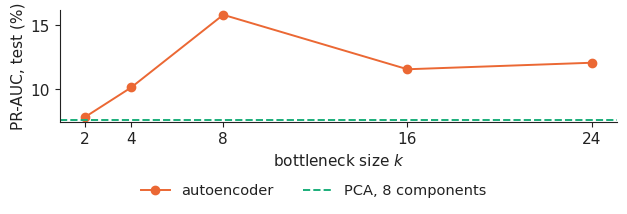

In [3]:
b = pd.read_csv(REPO + 'lectures/L8/results/' + 'ae_bottleneck.csv')
fr = pd.read_csv(REPO + 'lectures/L8/results/' + 'fraud_test_scores.csv')
from sklearn.metrics import average_precision_score
ap_pca = 100 * average_precision_score(fr.y, fr.err_pca, sample_weight=fr.weight)
show('ae.best_k', 'best bottleneck size', int(b.k[b.ap.idxmax()]))
fig, ax = plt.subplots(figsize=(6.4, 2.2))
ax.plot(b.k, 100 * b.ap, 'o-', color=PAL['model'], label='autoencoder')
ax.axhline(ap_pca, color=PAL['benchmark'], ls='--', label='PCA, 8 components')
ax.set_xticks(b.k)
ax.set_xlabel('bottleneck size $k$'); ax.set_ylabel('PR-AUC, test (%)')
legend_bottom(fig)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('ae_bottleneck.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()